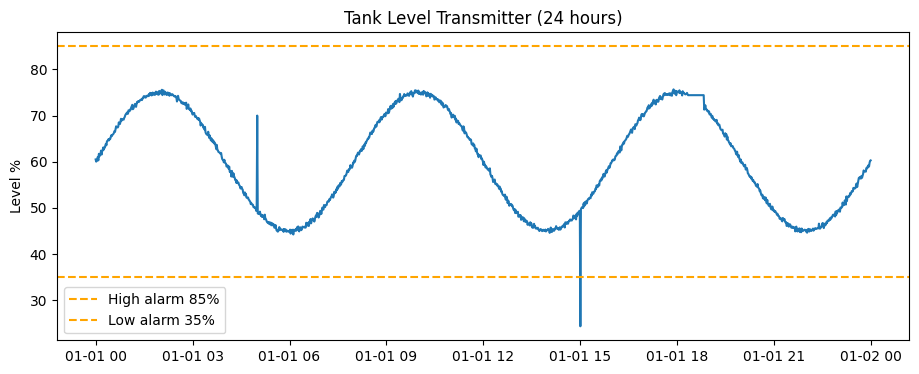

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)
n = 1440  # يوم كامل، قراءة كل دقيقة
time = pd.date_range("2026-01-01", periods=n, freq="min")

# مستوى الخزان الحقيقي (%): يعبّى وينزل خلال اليوم
level = 60 + 15 * np.sin(np.linspace(0, 6 * np.pi, n))

# قراءة الحساس = المستوى + ضوضاء صغيرة
pv = level + np.random.normal(0, 0.3, n)

# عطل 1: قفزة خاطئة بالحساس (spike)
pv[300] += 20
pv[900] -= 25

# عطل 2: الحساس يعلّق على قيمة ثابتة 30 دقيقة (stuck)
pv[1100:1130] = pv[1100]

df = pd.DataFrame({"time": time, "level_pct": pv})

plt.figure(figsize=(11, 4))
plt.plot(df["time"], df["level_pct"])
plt.axhline(85, color="orange", linestyle="--", label="High alarm 85%")
plt.axhline(35, color="orange", linestyle="--", label="Low alarm 35%")
plt.title("Tank Level Transmitter (24 hours)")
plt.ylabel("Level %")
plt.legend()
plt.show()

In [3]:
change = df["level_pct"].diff().abs()
df["spike"] = change > 5

Spike readings: 4
Stuck readings: 21


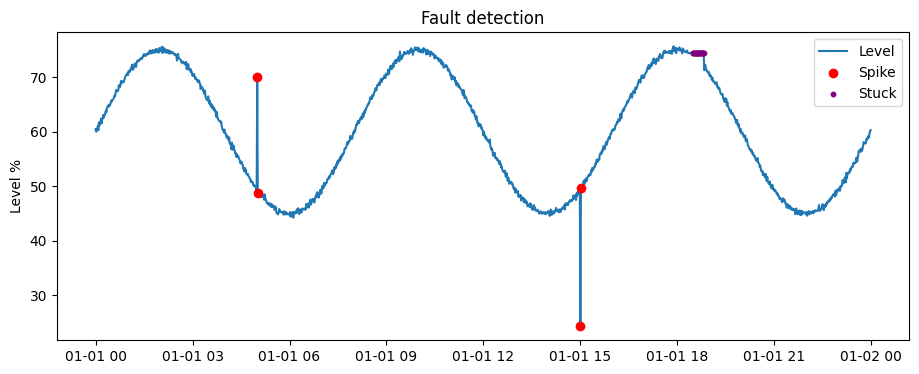

In [9]:
# 1) كشف القفزات: تغير مفاجئ بين قراءتين متتاليتين
change = df["level_pct"].diff().abs()
df["spike"] = change > 5

# 2) كشف الحساس المعلّق: التغير شبه صفر لمدة 10 دقائق متتالية
rolling_range = df["level_pct"].rolling(10).max() - df["level_pct"].rolling(10).min()
df["stuck"] = rolling_range < 0.01

print("Spike readings:", df["spike"].sum())
print("Stuck readings:", df["stuck"].sum())

plt.figure(figsize=(11, 4))
plt.plot(df["time"], df["level_pct"], label="Level")
plt.scatter(df[df["spike"]]["time"], df[df["spike"]]["level_pct"],
            color="red", label="Spike", zorder=3)
plt.scatter(df[df["stuck"]]["time"], df[df["stuck"]]["level_pct"],
            color="purple", s=10, label="Stuck", zorder=3)
plt.title("Fault detection")
plt.ylabel("Level %")
plt.legend()
plt.show()


In [5]:
print(df.loc[1095:1135, "level_pct"].round(3).tolist())
print(df.loc[1095:1135, "stuck"].tolist())

[74.575, 74.669, 74.642, 74.896, 74.605, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 74.409, 71.269, 71.628, 72.23, 71.447, 71.392, 71.043]
[False, False, False, False, False, False, False, False, False, False, False, False, False, False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, False, False, False, False, False, False]


In [10]:
print("Stuck readings:", df["stuck"].sum())


Stuck readings: 21
